## Домашнее задание 6

### Задача 1

Выведите линейный MPC для следования траектории $X = \{x_{i+1}^*\}_{i=0}^{N-1}$. Вывод слегка обобщает лекционный результат. 

YOUR MARKDOWN HERE

### Задача 2

Реализуйте функцию generate_controls, следуя выводу из первой задачи. Она должна генерировать для заданной системы последовательность управлений, оптимальную в смысле квадратичной функции стоимости.

In [ ]:
import numpy as np

def generate_controls(x_0, X_star, A, B, N, Q, R):
    #A_hat = np.zeros(...)
    
    #YOUR CODE BELOW
    
    #YOUR CODE ABOVE
        
    return U

A = np.array\
        ([[0, 1, 0,   0],
          [0, 0, 0.5, 0],
          [0, 0, 0,   1],
          [0, 0, 0.4, 0]])

B = np.array([[0], [0.5], [0], [1.0]])

Q = np.eye(4)

R = np.eye(1)

horizon = 3

x_0 = np.array([[10], [1], [2], [1]])

X_star = ...

print(generate_controls(x_0, X_star, A, B, horizon, Q, R))

### Задача 3

Реализуйте функцию generate_controls, поставив задачу поиска оптимальной последовательности управлений как задачу квадратичного программирования и решив ее с помощью *solve_qp*. Учтите ограничения на управление (F_max).

In [ ]:
import numpy as np
from qpsolvers import solve_qp

def generate_controls(x_0, X_star, A, B, N, Q, R, u_max):
    #YOUR CODE BELOW
    
    #YOUR CODE ABOVE
    
    U = solve_qp(C, d, E, f, solver="proxqp")
    
    return U

A = np.array\
        ([[0, 1, 0,   0],
          [0, 0, 0.5, 0],
          [0, 0, 0,   1],
          [0, 0, 0.4, 0]])

B = np.array([[0], [0.5], [0], [1.0]])

Q = np.eye(4)

R = np.eye(1)

horizon = 3

F_max = 2

x_0 = np.array([[10], [1], [2], [1]])
X_star = ...

print(generate_controls(x_0, X_star, A, B, horizon, Q, R, F_max))

### Задача 4

Примените функцию generate_controls для управления динамической точкой с массой. Визуализируйте результат.

In [ ]:
# YOUR CODE HERE



### Задача 5

Примените функцию generate_controls для управления линеаризованным Cart-pole. Ниже дана заготовка кода, ее нужно будет дополнить.

Система должна совершать колебания вокруг координаты, которую вы задаете на трекбаре.

Управление должно осуществляться с помощью MPC для линейной системы.

ВАЖНО! Управление должно быть согласно линейной модели, а вот интегрирование должно быть для полной (нелинейной) модели.

Рекомендуемый порядок действий:
- получите лагранжиан
- получите уравнения движения, добавьте в них управление
- выразите из них x_ddot, theta_ddot
- линейризуйте систему в окрестности верхнего положения равновесия
- запрогайте это, дописав матрицы в классе
- встройте в цикл симуляции генерацию управления согласно MPC
- сдвигайте ноль согласно положению, задаваемому трекбаром

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy import linalg
import copy
import math

def draw_cart_pole(cx, cy, x, alpha, scale = 100, color = (234, 123, 123), canvas = None,
                   alpha_0 = 0):
    if (canvas is None):
        canvas = np.ones((700, 700, 3)) * 0
    
    h, w, _ = canvas.shape
    
    cv2.line(canvas, (0, h // 2), (w, h // 2), color, 2)
    
    cv2.circle(canvas, (w // 2, h // 2), 7, color, 2)
    
    cv2.rectangle(canvas, (int(cx - w // 20 + x * scale), cy - h // 40),
                          (int(cx + w // 20 + x * scale), cy + h // 40), color, -1)
    
    cv2.line(canvas, (int(cx + x * scale), cy),
                     (int(cx + x * scale - w / 5 * math.sin(alpha + alpha_0)),
                          cy - int(w / 5 * math.cos(alpha + alpha_0))), color, 2)
    
    cv2.circle(canvas, (int(cx + x * scale - w / 5 * math.sin(alpha + alpha_0)),
                          cy - int(w / 5 * math.cos(alpha + alpha_0))), 27, color, 7)
    
    return canvas

class Cart_pole:
    def __init__(self, M = 1.0, m = 1.0, l = 3.0, g = 10.0,
                 a0 = 0.2, ad0 = -0.3, x0 = 1.2, xd0 = -0.1,
                 dt = 0.001, Q = np.eye(4), R = np.eye(1),
                 WIND_X = 700, scale = 100, max_goal_pos = 3):
        self.M = M
        self.m = m
        self.l = l
        self.g = g
        
        self.x = np.array([[x0], [xd0], [a0], [ad0]])
        self.dt = dt
                
        #YOUR CODE BELOW
        self.A = np.array()
        
        self.B = np.array()
        #YOUR CODE BELOW
        
        self.Q = Q
        self.R = R
                
        self.WIND_X = WIND_X
        self.scale = scale
        self.target_x = 0.0
        self.max_goal_pos = max_goal_pos
        
        cv2.namedWindow('cart_pole')
        cv2.createTrackbar("goal_position", "cart_pole", max_goal_pos,
                           max_goal_pos * 2,
                          lambda i : i)

    def get_state(self):
        return self.x
    
    def propagate_system(self, u):
        x  = self.x[0, 0]
        xd = self.x[1, 0]
        a  = self.x[2, 0]
        ad = self.x[3, 0]
        
        g = self.g
        M = self.M
        m = self.m
        l = self.l
        
        add = (g * (M + m) * math.sin(a) + (u - m * l * ad**2 * math.sin(a)) * math.cos(a)) / (l * (M + m * math.sin(a)**2))
        xdd = 1.0 / (M + m) * (u + m * l * add * math.cos(a) - m * l * ad**2 * math.sin(a))
        
        self.x[1, 0] += xdd * self.dt
        self.x[0, 0] += self.x[1, 0] * self.dt
        
        self.x[3, 0] += add * self.dt
        self.x[2, 0] += self.x[3, 0] * self.dt

def state_action_cost(x, u, Q, R):
    cost = x.T @ Q @ x + u.T @ R @ u
    
    return cost

def episode_cost(x_hist, u_hist, Q, R):
    total_cost = 0
    cost_hist = []
    
    for x, u in zip(x_hist, u_hist):
        cost = state_action_cost(x, u, Q, R)
        
        total_cost += cost
        cost_hist.append(cost)
    
    return total_cost, cost_hist

def run_cart_pole_episode(Q, R, a0 = 0.2, ad0 = -0.3, x0 = 1.2, xd0 = -0.1,
                          scale = 30, max_goal_pos = 10):
    WIND_X = 700
    WIND_Y = 700
    canvas = np.ones((700, 700, 3), np.uint8) * 70
    
    dyn_point = Cart_pole(M = 1.0, m = 1.0, l = 1.0, g = 10.0,
                 a0 = a0, ad0 = ad0, x0 = x0, xd0 = xd0,
                 dt = 0.15, Q = Q, R = R, WIND_X = WIND_X,
                 scale = scale, max_goal_pos = max_goal_pos)

    iter_num = 750000
    i = 0

    x_traj = []
    v_traj = []
    u_traj = []
    
    Q = np.eye(4) * 1
        
    R = np.eye(1)
    
    horizon = 10

    F_max = 20
    
    def get_A(dt):
        M = 1.0
        m = 1.0
        l = 1.0
        g = 10.0
        
        return np.array ...
    
    while(True):
        state = dyn_point.get_state()
        
        target = cv2.getTrackbarPos("goal_position", "cart_pole")
        
        
        #controls = generate_controls(state - np.array([[target - max_goal_pos + 7 * math.sin(i / 5.0)],
        #                            [0], [0], [0]]), get_A(0.5), dyn_point.B * 0.5, horizon, Q, R, F_max)
        
        # YOUR CODE BELOW
        
        controls = 
        
        # YOUR CODE ABOVE
        
        control = controls[0]
        
        dyn_point.propagate_system(control)
                
        x_traj.append(state)
        u_traj.append(control)
        
        canvas = cv2.addWeighted(canvas, 0.85, canvas, 0, 0)
        draw_cart_pole(WIND_X // 2, WIND_Y // 2, state[0, 0], state[2, 0],
                       canvas = canvas, scale = scale)

        cv2.imshow("cart_pole", canvas)
        
        i += 1

        if (i > iter_num):
            break
        
        key = cv2.waitKey(10) & 0xFF
        
        if (key == ord('q')):
            break
    
    cv2.destroyAllWindows()
    cv2.waitKey(10)
    
    return x_traj, u_traj

Q = np.eye(4)
Q[0, 0] *= 10
R = np.eye(1) * 1

x_hist, u_hist = run_cart_pole_episode(Q, R, a0 = -0.2, ad0 = 0.01,
                x0 = 0.4, xd0 = 0.1, max_goal_pos = 10)

### Задача 6

Нужно будет пользоваться кодом с семинара, он лежит в репозитории.

Будем рассматривать обратный маятник длиной 1 $м$ с грузом 1 $кг$ в поле тяготения 10 $м/с^2$, просимулированный с шагом 0.01 $с$.

Реализуйте контроллер, который стабилизирует обратный маятник из начального состояния (3.0, 0) за как можно меньшее время (пока что просто на вид)

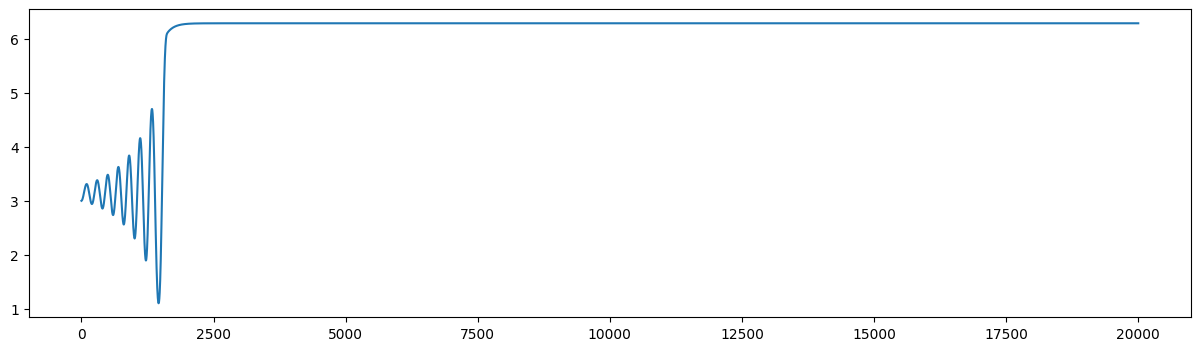

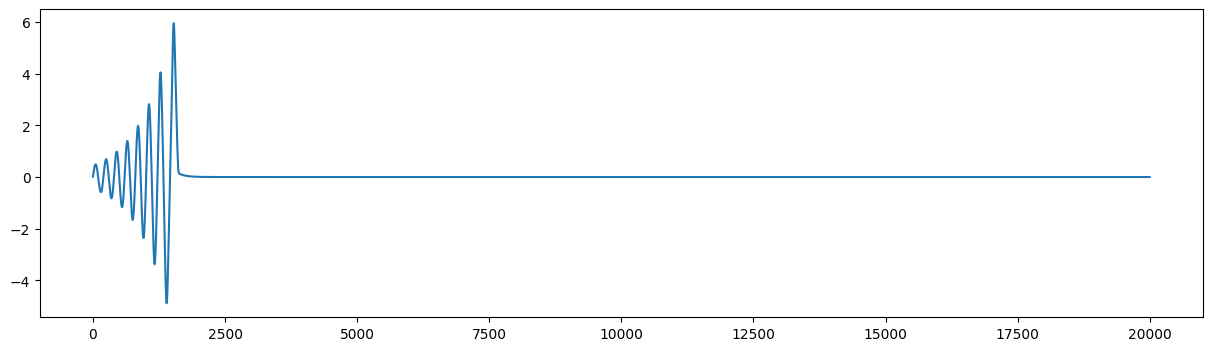

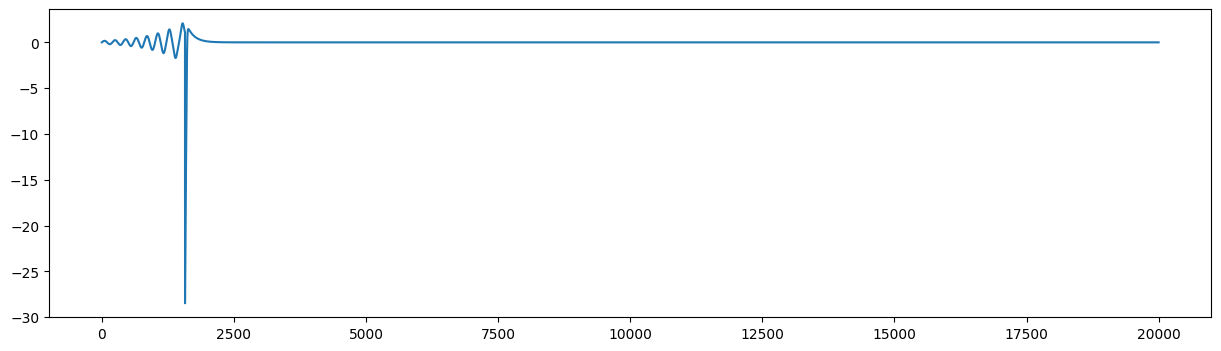

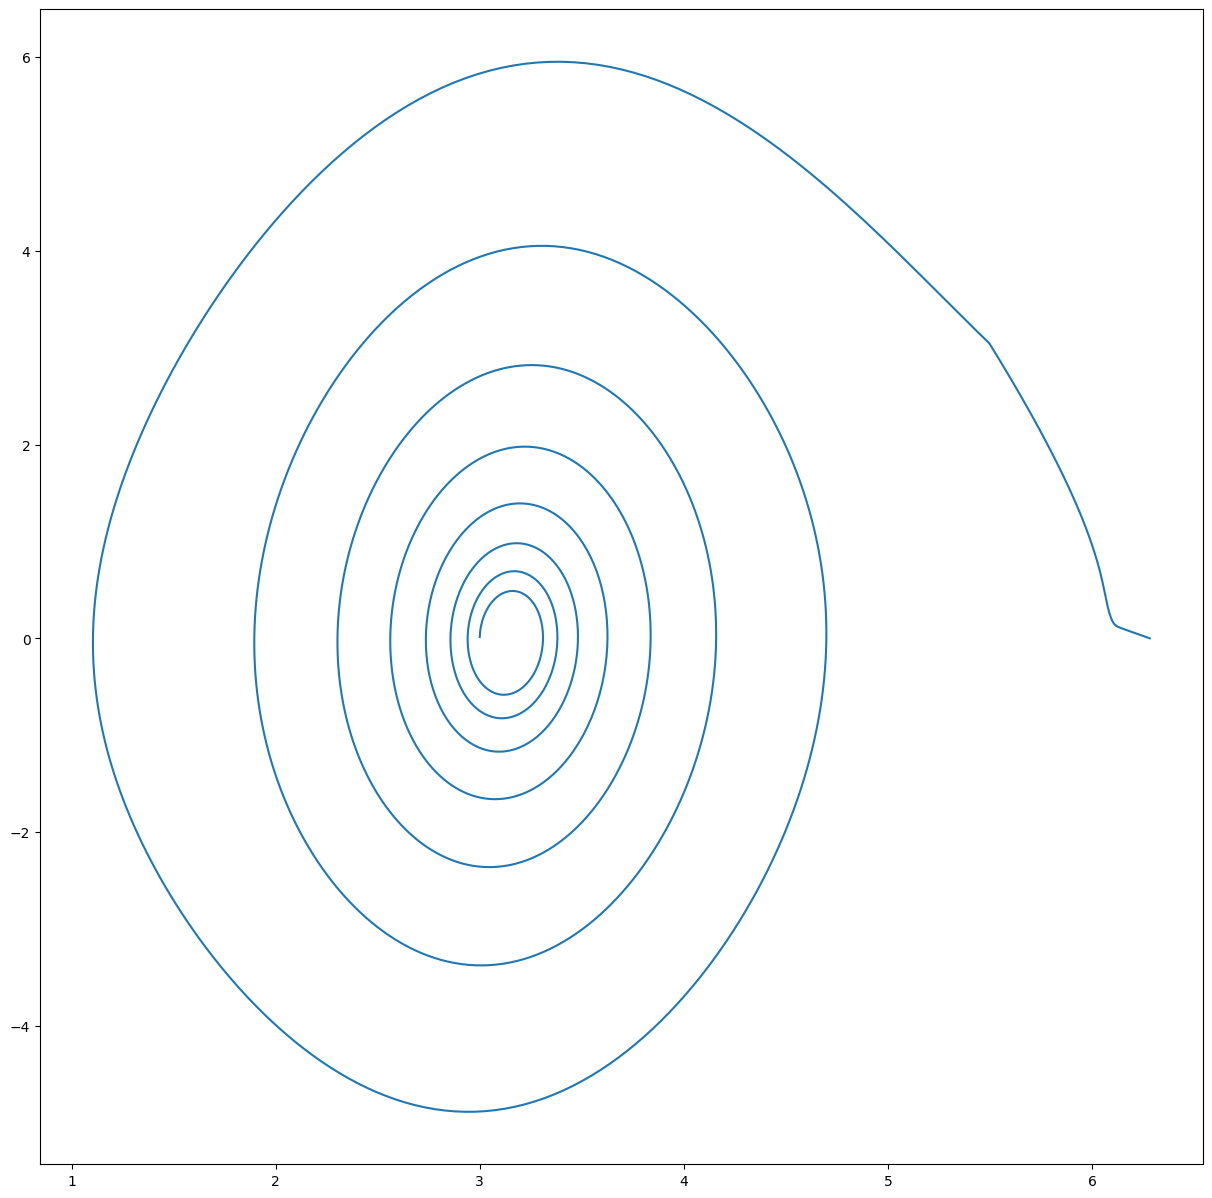

In [2]:
import numpy as np
import math
import cv2
import matplotlib.pyplot as plt
from ipywidgets import interact
from IPython.display import display, clear_output

def plot_1d(data):
    plt.figure(figsize=(15, 4))
    plt.plot(data)
    plt.show()

class Pendulum:
    def __init__(self, m = 1.0, l = 1.0, g = 10.0, x0 = 3, v0 = 0.0, dt = 0.01, max_torque = 3):
        self.m = m
        self.l = l
        self.g = g
        
        self.x = np.array([[x0], [v0]])
        self.dt = dt
        self.max_torque = max_torque
        
    def get_state(self):
        return self.x
    
    def sys_dyn(self, u_scalar):
        x_dot = np.zeros_like(self.x)
        
        u_effective = np.clip(u_scalar, -self.max_torque, self.max_torque)
        #u_effective = u_scalar        
        x_dot[0, 0] = self.x[1, 0]
        x_dot[1, 0] = self.g / self.l * np.sin(self.x[0, 0]) + u_effective / (self.m * self.l**2)
        
        return x_dot
    
    def integrate_sys_dyn(self, sys_dyn):        
        self.x[1] += sys_dyn[1] * self.dt
        self.x[0] += self.x[1] * self.dt

def draw_pendulum(canvas, x, y, l, alpha, color = (123, 234, 234),
                  inverted = False):
    direction = -1
    
    if (inverted == True):
        direction = 1
    
    endpoint = (int(x - l * np.cos(alpha + direction * np.pi / 2)),
                int(y + l * np.sin(alpha + direction * np.pi / 2)))
    
    cv2.line(canvas, (x, y), endpoint, (123, 234, 234), 5)
    
    cv2.circle(canvas, endpoint, 25, color, -1)

def run_pendulum(x0, iter_num, visualize, control_function, max_torque = 3, dt = 0.01):
    if (visualize == True):
        WIND_X = 700
        WIND_Y = 700
        canvas = np.ones((700, 700, 3), np.uint8) * 70
        
    pendulum = Pendulum(x0 = x0, dt = dt)

    i = 0

    x_traj = []
    v_traj = []
    u_traj = []
    
    while(True):
        state = pendulum.get_state()

        control = control_function(state, max_torque)
        
        x_dot = pendulum.sys_dyn(control)
                
        pendulum.integrate_sys_dyn(x_dot)
        
        x_traj.append(state[0, 0])
        v_traj.append(state[1, 0])
        u_traj.append(control)
        
        i += 1

        if (i > iter_num):
            break

        if (visualize == True):
            canvas = cv2.addWeighted(canvas, 0.93, canvas, 0, 0)

            draw_pendulum(canvas, WIND_X // 2, WIND_Y // 2, 300,
                          state[0, 0], (123, 234, 45), inverted = False)

            cv2.imshow("pendulum", canvas)

            if (i == 1):
                cv2.waitKey(0)

            key = cv2.waitKey(10) & 0xFF

            if (key == ord('q')):
                break
    
    if (visualize == True):
        cv2.destroyAllWindows()
        cv2.waitKey(10)
    
    return x_traj, v_traj, u_traj

def stabilizing_control(x, max_tau = 5):
    u = - 5 * x[1, 0]
    
    return u

def destabilizing_control(x, max_tau = 5):
    u = 0.1 * x[1, 0]
    
    return u

def unlimited_up_control(x, max_tau = 5):
    return - 14 * np.sin(x[0, 0]) - 35 * x[1, 0]

def swing_up_control(x, max_tau = 5):
    u = - 20 * np.sin(x[0, 0]) - 14 * x[1, 0]  # -15 -14  -20 -14
    
    if (np.cos(x[0, 0]) < 0.7):
        u = 0.35 * x[1, 0]
    
    return u

#x_hist, v_hist, u_hist = run_pendulum(x0 = 3, iter_num = 10000, visualize = True, control_function = lambda i, j : 3, max_torque = 3)
#x_hist, v_hist, u_hist = run_pendulum(x0 = 3.1415, iter_num = 20000, visualize = True, control_function = swing_up_control, max_torque = 3, dt = 0.01)

#x_hist, v_hist, u_hist = run_pendulum(x0 = 1, iter_num = 20000, visualize = True, control_function = stabilizing_control, max_torque = 3, dt = 0.01)
#x_hist, v_hist, u_hist = run_pendulum(x0 = 3, iter_num = 20000, visualize = True, control_function = destabilizing_control, max_torque = 3, dt = 0.01)
#x_hist, v_hist, u_hist = run_pendulum(x0 = 3, iter_num = 20000, visualize = False, control_function = unlimited_up_control, max_torque = 300000, dt = 0.01)
x_hist, v_hist, u_hist = run_pendulum(x0 = 3, iter_num = 20000, visualize = False, control_function = swing_up_control, max_torque = 3, dt = 0.01)

plot_1d(x_hist)
plot_1d(v_hist)
plot_1d(u_hist)

plt.figure(figsize=(15, 15))
plt.plot(x_hist, v_hist)
plt.show()
clear_output(wait = True)


### Задача 7

Реализуйте функцию, в которую передается история угла маятника от времени, и она возвращает, начиная с какого момента угол отклонения маятника не превышал $\varepsilon$ (это тоже входной параметр).

Измерьте время стабилизации своим контроллером при $\varepsilon = 0.1$ рад.

In [3]:
def get_stabilisation_timestamp(x_hist, dt, eps):
    stab = False
    stab_ts = 10**4
    for i in range(len(x_hist)):
        #print(, abs(abs((x_hist[i] % (math.pi*2))) - math.pi*2))
        if stab == False and abs(abs((x_hist[i] % (math.pi*2))) - math.pi*2) <= eps:
            stab = True
            stab_ts = dt * i
        elif abs(abs((x_hist[i] % (math.pi*2))) - math.pi*2) > eps:
            stab = False
            stab_ts = 10**4
    return stab_ts


get_stabilisation_timestamp(x_hist, 0.01, 0.1)

17.03

### Задача 8

Реализуйте функцию, которая многократно запускает симуляцию с разными начальными состояниями и находит максимальное время стабилизации среди этих запусков. Рассмотрите 20 разных начальных значений угла от $-\pi$ до $\pi$ и 20 разных значений скорости от $-10$ рад./с до $-10$ рад./с. Нарисуйте время стабилизации для разных начальных условий в виде тепловой карты.

In [4]:
x_linspace = np.linspace(-math.pi, math.pi, 20)
torque_linspace = np.linspace(-10, 10, 20)
stab_ts_matrix = []

for x in x_linspace:
    stab_ts_matrix.append([])
    for t in torque_linspace:
        x_hist, v_hist, u_hist = run_pendulum(x0 = x, iter_num = 7000, visualize = False, control_function = swing_up_control, max_torque = t, dt = 0.01)
        stab_ts_matrix[-1].append(get_stabilisation_timestamp(x_hist, 0.01, 0.1))

In [5]:
stab_ts_matrix

[[10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000],
 [12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82,
  12.82],
 [10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000],
 [6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63,
  6.63],
 [10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000],
 [10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000,
  10000

ValueError: 'stab_ts_matrix' is not a valid value for cmap; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r', 'cool', 'cool_r', 'coo

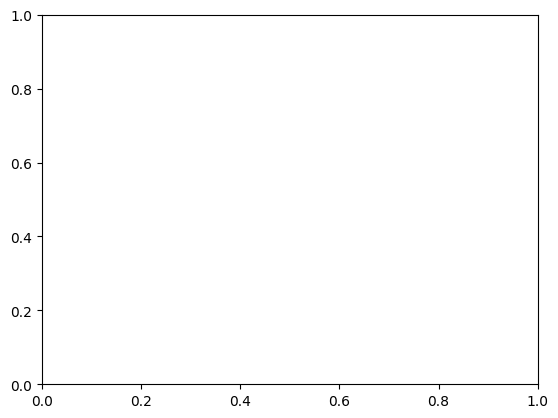

In [7]:
plt.imshow(stab_ts_matrix, cmap='stab_ts_matrix')
plt.xlabel('x0')
plt.ylabel('torque')
plt.show()